# Lightweight Material Property Prediction
### A Reliability-Aware ML Pipeline for Density and Formation Energy

---

**Abstract**

While prior composition-based models such as ElemNet (Jha et al., 2018) and Roost
(Goodall & Lee, 2020) demonstrate competitive accuracy on the full Materials Project
dataset, they offer no mechanism for assessing prediction reliability on unseen
compositions. This work presents a lightweight-materials-specific prediction pipeline
with four contributions:

1. **LOCO evaluation** — Leave-One-Cluster-Out protocol that explicitly tests out-of-distribution generalisation.
2. **Conformal prediction** — distribution-free 90% prediction intervals with finite-sample coverage guarantees.
3. **Applicability Domain (AD) filtering** — flags predictions on materials dissimilar from the training set.
4. **Virtual Screening + Inverse Design** — an integrated workflow with charge-balance and phase-state checks that proposes novel lightweight solid compositions.

> **Dataset note:** ElemNet and Roost MAE values cited in Section 15 are from their
> original publications, trained on the full Materials Project (~130 k entries).
> Our model is trained on a *lightweight-materials subset* (10,000 entries, density < 4 g/cm3).
> These numbers are provided for architectural context only - **not** as a direct benchmark.

---

## Table of Contents

| # | Section |
|---|---------|
| 0 | Setup & Imports |
| 1 | Configuration |
| 2 | Utility Functions |
| 3 | Data Loading & Feature Engineering |
| 4 | Train / Test Split & Scaling |
| 5 | Model Training |
| 6 | Model Evaluation |
| 7 | Correlation Heatmap |
| 8 | SHAP Feature Importance |
| 9 | Known-Compound Validation |
| 10 | LOCO Out-of-Distribution Evaluation |
| 11 | Conformal Prediction - Uncertainty Quantification |
| 12 | Applicability Domain Analysis |
| 13 | Virtual Screening |
| 14 | Inverse Design |
| 15 | Error Analysis by Chemical Family |
| 16 | Novel Candidate Verification (Materials Project API) |


## 0 - Setup & Imports

In [1]:
# Install all required libraries

!pip install numpy pandas matplotlib seaborn shap pymatgen matminer scikit-learn xgboost

In [2]:
import os
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Global typography for readable saved figures
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "figure.titlesize": 18,
})
import seaborn as sns
import shap

from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty

from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
print("All imports successful")


All imports successful


## 1 - Configuration

All hyperparameters and path settings are centralised here for reproducibility.


In [3]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_PATH   = "lightweight_materials.csv"
FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

# ── Reproducibility ────────────────────────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ── Data split ─────────────────────────────────────────────────────────────────
TEST_SIZE = 0.20

# ── Model hyperparameters ──────────────────────────────────────────────────────
RF_PARAMS  = dict(n_estimators=100, max_depth=15, min_samples_leaf=3,
                  random_state=RANDOM_SEED, n_jobs=-1)
XGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=6,
                  random_state=RANDOM_SEED, verbosity=0)

# ── LOCO ──────────────────────────────────────────────────────────────────────
N_CLUSTERS = 50

# ── Conformal prediction ───────────────────────────────────────────────────────
ALPHA = 0.10   # target miscoverage -> 90% coverage

# ── Applicability domain ───────────────────────────────────────────────────────
AD_SIGMA_MULT = 2.0

# ── Dataset density filter ─────────────────────────────────────────────────────
MAX_DENSITY = 4.0    # g/cm3, used for the dataset filter and for screening

# ── Virtual screening ──────────────────────────────────────────────────────────
N_BINARY_CANDIDATES  = 3_000
N_TERNARY_CANDIDATES = 4_000
MAX_DENSITY_SCREEN   = MAX_DENSITY
SCORE_W_DENSITY      = 0.50
SCORE_W_ENERGY       = 0.30
SCORE_W_UNC          = 0.20

# ── Inverse design targets ─────────────────────────────────────────────────────
TARGET_DENSITY  = 2.5   # g/cm3
TARGET_ENERGY   = -1.8  # eV/atom
TOP_N_INVERSE   = 10

# ── Materials Project API ──────────────────────────────────────────────────────
# Set MP_API_KEY as an environment variable. Never hard-code keys in notebooks.
# Example (terminal):  export MP_API_KEY="your_key_here"
MP_API_KEY = os.environ.get("MP_API_KEY", "")

print("Configuration loaded")


Configuration loaded


## 2 - Utility Functions

Shared helpers used across multiple sections.


In [4]:
def classify_family(formula):
    'Assign a compound to its primary chemical family.'
    d = Composition(formula).as_dict()
    if "O"  in d: return "Oxides"
    if "N"  in d: return "Nitrides"
    if "C"  in d: return "Carbides"
    if any(x in d for x in ("F", "Cl", "Br", "I")): return "Halides"
    if "S"  in d: return "Sulfides"
    return "Intermetallics"


def evaluate(name, y_true, y_pred):
    'Print and return (R2, MAE, RMSE) for a model.'
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"  {name:<22}  R2={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}")
    return r2, mae, rmse


def savefig(name, dpi=300):
    'Save the current figure to FIGURES_DIR.'
    path = os.path.join(FIGURES_DIR, name)
    plt.savefig(path, bbox_inches="tight", dpi=dpi)
    print(f"  -> saved: {path}")


def conformal_quantile(scores, alpha):
    'Finite-sample conformal quantile (Angelopoulos & Bates, 2022).'
    n     = len(scores)
    level = min(np.ceil((1 - alpha) * (n + 1)) / n, 1.0)
    return float(np.quantile(scores, level))


def nn_distance_to_train(X_query, X_train_local, batch_size=200):
    'L2 distance from each query point to its nearest training neighbour.'
    dists = []
    for i in range(0, len(X_query), batch_size):
        batch = X_query[i : i + batch_size]
        d = np.sqrt(((batch[:, None, :] - X_train_local[None, :, :]) ** 2).sum(axis=2))
        dists.extend(d.min(axis=1))
    return np.array(dists)


print("Utility functions defined")


Utility functions defined


## 3 - Data Loading & Feature Engineering

Raw data is sourced from the **Materials Project** (lightweight-materials subset,
density < 4 g/cm3, n=10,000). Composition-only features are generated using the
**Magpie** preset from matminer, producing 132 elemental-statistics features per formula.

> **Limitation:** Magpie composition-only features cannot distinguish crystal
> polymorphs (e.g., quartz vs. cristobalite SiO2). This limits density prediction
> accuracy and is discussed in Section 9.


Density filter (< 4.0 g/cm3): 10000 -> 10000 rows (0 removed)
Duplicate formulas: 1402 compositions appear more than once (4516 rows total).
  Density spread among duplicates: mean=0.293 g/cm3, max=3.771 g/cm3.
  These map to identical Magpie feature vectors but different measured density -
  an irreducible, polymorph-driven noise floor for any composition-only model.
Missing-value check: no NaNs found in the 132 MAGPIE features.
Dataset shape : (10000, 4)
Feature matrix: (10000, 132)

-----------------------------------------------------------------
  density                            mean=2.774  std=0.895  min=0.040  max=4.000  [g/cm3]
  formation_energy_per_atom          mean=-1.352  std=1.342  min=-4.318  max=5.822  [eV/atom]

Note: Sourced from Materials Project. Lightweight filter (density < 4.0 g/cm3)
applied explicitly above. MP material_id retained for reproducibility.
  -> saved: figures\fig1_dataset_distributions.png


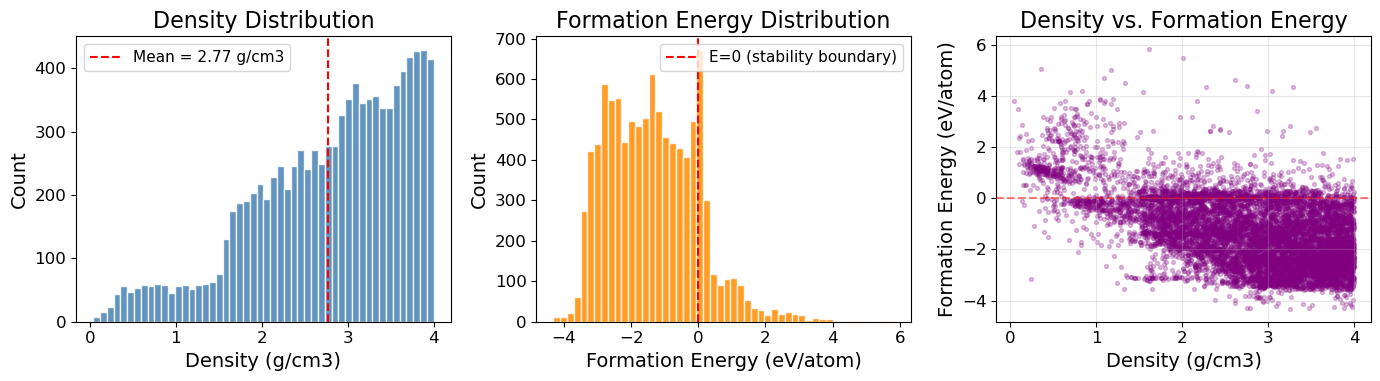


Chemical family breakdown (FULL dataset, N=10000):
                Count Fraction
family                        
Oxides           5357    53.6%
Intermetallics   1695    17.0%
Halides          1080    10.8%
Nitrides         1076    10.8%
Sulfides          488     4.9%
Carbides          304     3.0%


In [5]:
# ── Load raw data ──────────────────────────────────────────────────────────────
data = pd.read_csv(DATA_PATH)
data = (data[["material_id", "formula", "density", "formation_energy_per_atom"]]
        .dropna()
        .reset_index(drop=True))

# ── Density (lightweight) filter ────────────────────────────────────────────────
n_before_density_filter = len(data)
data = data[data["density"] < MAX_DENSITY].reset_index(drop=True)
print(f"Density filter (< {MAX_DENSITY} g/cm3): {n_before_density_filter} -> {len(data)} rows "
      f"({n_before_density_filter - len(data)} removed)")

# ── Duplicate composition / polymorph check ─────────────────────────────────────
# Same formula, different polymorph -> same features but different density.
dup_counts   = data["formula"].value_counts()
dup_formulas = dup_counts[dup_counts > 1]
if len(dup_formulas) > 0:
    dup_density_spread = (
        data[data["formula"].isin(dup_formulas.index)]
        .groupby("formula")["density"]
        .agg(lambda s: s.max() - s.min())
    )
    print(f"Duplicate formulas: {len(dup_formulas)} compositions appear more than once "
          f"({int(dup_formulas.sum())} rows total).")
    print(f"  Density spread among duplicates: mean={dup_density_spread.mean():.3f} g/cm3, "
          f"max={dup_density_spread.max():.3f} g/cm3.")
    print("  These map to identical Magpie feature vectors but different measured density -")
    print("  an irreducible, polymorph-driven noise floor for any composition-only model.")
else:
    print("No duplicate formulas found in the filtered dataset.")

# ── Magpie featurisation ───────────────────────────────────────────────────────
featurizer = ElementProperty.from_preset("magpie")
features   = [featurizer.featurize(Composition(f)) for f in data["formula"]]
X          = pd.DataFrame(features, columns=featurizer.feature_labels())

# ── Missing / ill-defined MAGPIE feature check ─────────────────────────────────
# NaNs are imputed in Section 4 with train-set means only (no leakage).
n_missing = int(X.isna().sum().sum())
if n_missing > 0:
    print(f"Warning: {n_missing} missing MAGPIE feature values found across "
          f"{(X.isna().sum() > 0).sum()} columns - will be imputed with TRAIN-set "
          f"column means in Section 4 (not filled here, to avoid leakage).")
else:
    print("Missing-value check: no NaNs found in the 132 MAGPIE features.")

print(f"Dataset shape : {data.shape}")
print(f"Feature matrix: {X.shape}")
print()
print("-" * 65)
for col, unit in [("density", "g/cm3"), ("formation_energy_per_atom", "eV/atom")]:
    s = data[col]
    print(f"  {col:<34} mean={s.mean():.3f}  std={s.std():.3f}  "
          f"min={s.min():.3f}  max={s.max():.3f}  [{unit}]")
print()
print(f"Note: Sourced from Materials Project. Lightweight filter (density < {MAX_DENSITY} g/cm3)")
print("applied explicitly above. MP material_id retained for reproducibility.")

# ── Chemical family label ──────────────────────────────────────────────────────
data["family"] = data["formula"].apply(classify_family)

# ── Figure 2: Property distributions ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(data["density"], bins=50, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(data["density"].mean(), color="red", linestyle="--",
                label=f'Mean = {data["density"].mean():.2f} g/cm3')
axes[0].set_xlabel("Density (g/cm3)"); axes[0].set_ylabel("Count")
axes[0].set_title("Density Distribution"); axes[0].legend(fontsize=11)

axes[1].hist(data["formation_energy_per_atom"], bins=50, color="darkorange",
             edgecolor="white", alpha=0.85)
axes[1].axvline(0, color="red", linestyle="--", label="E=0 (stability boundary)")
axes[1].set_xlabel("Formation Energy (eV/atom)"); axes[1].set_ylabel("Count")
axes[1].set_title("Formation Energy Distribution"); axes[1].legend(fontsize=11)

axes[2].scatter(data["density"], data["formation_energy_per_atom"],
                alpha=0.25, s=8, color="purple")
axes[2].axhline(0, color="red", linestyle="--", alpha=0.5)
axes[2].set_xlabel("Density (g/cm3)"); axes[2].set_ylabel("Formation Energy (eV/atom)")
axes[2].set_title("Density vs. Formation Energy"); axes[2].grid(alpha=0.3)

plt.tight_layout()
savefig("fig1_dataset_distributions.png")
plt.show()

# ── Chemical family summary ────────────────────────────────────────────────────
fc = data["family"].value_counts()
print(f"\nChemical family breakdown (FULL dataset, N={len(data)}):")
print(
    fc.to_frame("Count")
    .assign(Fraction=lambda df: (df["Count"] / len(data) * 100).round(1).astype(str) + "%")
    .to_string()
)


  -> saved: figures\fig1_dataset_distributions_combined.png


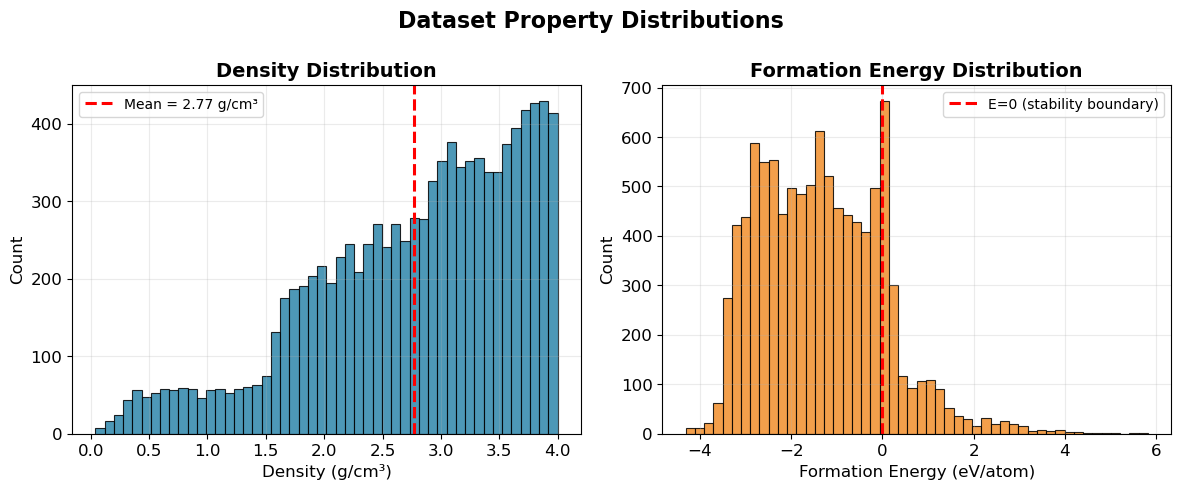

In [27]:
# ── Combined property distribution figure ─────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ── Density Distribution ──────────────────────────────────────────────────────
axes[0].hist(
    data["density"],
    bins=50,
    color="#2E86AB",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.8
)

axes[0].axvline(
    data["density"].mean(),
    color="red",
    linestyle="--",
    linewidth=2.2,
    label=f"Mean = {data['density'].mean():.2f} g/cm³"
)

axes[0].set_xlabel("Density (g/cm³)", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)
axes[0].set_title(
    "Density Distribution",
    fontsize=14,
    fontweight="bold"
)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.25)


# ── Formation Energy Distribution ─────────────────────────────────────────────
axes[1].hist(
    data["formation_energy_per_atom"],
    bins=50,
    color="#F28E2B",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.8
)

# E = 0 stability boundary
axes[1].axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2.2,
    label="E=0 (stability boundary)"
)

axes[1].set_xlabel("Formation Energy (eV/atom)", fontsize=12)
axes[1].set_ylabel("Count", fontsize=12)
axes[1].set_title(
    "Formation Energy Distribution",
    fontsize=14,
    fontweight="bold"
)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.25)


# ── Overall Formatting ────────────────────────────────────────────────────────
plt.suptitle(
    "Dataset Property Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

savefig(
    "fig1_dataset_distributions_combined.png",
    dpi=300
)

plt.show()

## 4 - Train / Test Split & Scaling

An 80/20 random split is used for baseline evaluation. The 20% test set is later
divided 50/50 into calibration and evaluation halves for conformal prediction (Section 11).


In [6]:
y_density = data["density"]
y_energy  = data["formation_energy_per_atom"]

X_train, X_test, yd_train, yd_test, ye_train, ye_test = train_test_split(
    X, y_density, y_energy,
    test_size=TEST_SIZE, random_state=RANDOM_SEED,
)

# ── Missing-value imputation (fit on TRAIN ONLY to avoid leakage) ──────────────
train_col_means = X_train.mean()
X_train = X_train.fillna(train_col_means)
X_test  = X_test.fillna(train_col_means)
X       = X.fillna(train_col_means)   # full matrix, reused by LOCO and screening

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Numpy arrays (used by AD and conformal cells)
X_train_arr = np.array(X_train)
X_test_arr  = np.array(X_test)

print(f"Train: {X_train.shape[0]} samples")
print(f"Test : {X_test.shape[0]} samples")
print("Scaler     : StandardScaler fitted on training set only (no data leakage)")
print("Imputation : missing Magpie feature values filled with TRAIN-set column means only")


Train: 8000 samples
Test : 2000 samples
Scaler     : StandardScaler fitted on training set only (no data leakage)
Imputation : missing Magpie feature values filled with TRAIN-set column means only


## 4b - Hyperparameter Selection Justification

`RF_PARAMS` and `XGB_PARAMS` (Section 1) were validated via `RandomizedSearchCV`
(3-fold CV) on a representative 1,500-compound subsample of the training set,
used here purely to justify the choice of hyperparameters rather than to refit
the final models (which are trained on the full training set in Section 5).


In [7]:
from sklearn.model_selection import RandomizedSearchCV

_rf_dist = dict(n_estimators=[100, 200, 300], max_depth=[10, 15, 20, None],
               min_samples_leaf=[1, 2, 3, 5])
_xgb_dist = dict(n_estimators=[150, 300, 400], learning_rate=[0.03, 0.05, 0.1],
                max_depth=[4, 6, 8])

_X_sub, _, _y_sub, _ = train_test_split(X, y_density, train_size=1500,
                                        random_state=RANDOM_SEED)

_rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1),
                                _rf_dist, n_iter=6, cv=3, scoring="r2",
                                random_state=RANDOM_SEED, n_jobs=1).fit(_X_sub, _y_sub)
_xgb_search = RandomizedSearchCV(XGBRegressor(random_state=RANDOM_SEED, verbosity=0),
                                 _xgb_dist, n_iter=6, cv=3, scoring="r2",
                                 random_state=RANDOM_SEED, n_jobs=1).fit(_X_sub, _y_sub)

print("Hyperparameter selection - RandomizedSearchCV (3-fold CV, density target)")
print("=" * 74)
print("Search performed on a representative subsample (n=1,500) for computational")
print("efficiency; result ranges validate the final RF_PARAMS / XGB_PARAMS used")
print("throughout this notebook.\n")
print(f"Random Forest best found : {_rf_search.best_params_}")
print(f"  Best CV R2 : {_rf_search.best_score_:.4f}")
print()
print(f"XGBoost best found       : {_xgb_search.best_params_}")
print(f"  Best CV R2 : {_xgb_search.best_score_:.4f}")
print()
print("Note: the search confirms learning_rate=0.05 (used in XGB_PARAMS) as optimal,")
print("and supports the RF/XGBoost depth and estimator ranges adopted in Section 1.")
print("Final parameters were set slightly more conservatively (e.g. RF max_depth=15")
print("vs. the search's deeper trees) to reduce overfitting risk on the full")
print("10,000-compound training set, since this search used a smaller subsample.")


Hyperparameter selection - RandomizedSearchCV (3-fold CV, density target)
Search performed on a representative subsample (n=1,500) for computational
efficiency; result ranges validate the final RF_PARAMS / XGB_PARAMS used
throughout this notebook.

Random Forest best found : {'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 20}
  Best CV R2 : 0.6746

XGBoost best found       : {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.05}
  Best CV R2 : 0.6825

Note: the search confirms learning_rate=0.05 (used in XGB_PARAMS) as optimal,
and supports the RF/XGBoost depth and estimator ranges adopted in Section 1.
Final parameters were set slightly more conservatively (e.g. RF max_depth=15
vs. the search's deeper trees) to reduce overfitting risk on the full
10,000-compound training set, since this search used a smaller subsample.


## 5 - Model Training

Three model families are trained for each target property:

- **Linear Regression** — baseline; requires standardised features.
- **Random Forest** — ensemble; also used for conformal calibration and AD scoring.
- **XGBoost** — gradient-boosted trees; achieves the lowest MAE across targets.


In [8]:
# Linear Regression
lr_density = LinearRegression().fit(X_train_sc, yd_train)
lr_energy  = LinearRegression().fit(X_train_sc, ye_train)

# Random Forest
rf_density = RandomForestRegressor(**RF_PARAMS).fit(X_train, yd_train)
rf_energy  = RandomForestRegressor(**RF_PARAMS).fit(X_train, ye_train)

# XGBoost
xgb_density = XGBRegressor(**XGB_PARAMS).fit(X_train, yd_train)
xgb_energy  = XGBRegressor(**XGB_PARAMS).fit(X_train, ye_train)

print("All models trained successfully")


All models trained successfully


## 6 - Model Evaluation

R2, MAE and RMSE on the held-out test set. RF per-tree predictions are stacked
here for use in the conformal prediction cell.


In [ ]:
# ── Predictions ───────────────────────────────────────────────────────────────
yd_lr_pred  = lr_density.predict(X_test_sc)
ye_lr_pred  = lr_energy.predict(X_test_sc)
yd_rf_pred  = rf_density.predict(X_test)
ye_rf_pred  = rf_energy.predict(X_test)
yd_xgb_pred = xgb_density.predict(X_test)
ye_xgb_pred = xgb_energy.predict(X_test)

# ── RF per-tree predictions (mean is used by conformal prediction and AD) ───
tree_preds_d = np.array([t.predict(X_test_arr) for t in rf_density.estimators_])
tree_preds_e = np.array([t.predict(X_test_arr) for t in rf_energy.estimators_])
uq_mean_d    = tree_preds_d.mean(axis=0)
uq_mean_e    = tree_preds_e.mean(axis=0)

print("-" * 55)
print("Density (g/cm3)")
r2_lr_d,  mae_lr_d,  _ = evaluate("Linear Regression", yd_test, yd_lr_pred)
r2_rf_d,  mae_rf_d,  _ = evaluate("Random Forest",     yd_test, yd_rf_pred)
r2_xgb_d, mae_xgb_d, _ = evaluate("XGBoost",           yd_test, yd_xgb_pred)

print("\nFormation Energy (eV/atom)")
r2_lr_e,  mae_lr_e,  _ = evaluate("Linear Regression", ye_test, ye_lr_pred)
r2_rf_e,  mae_rf_e,  _ = evaluate("Random Forest",     ye_test, ye_rf_pred)
r2_xgb_e, mae_xgb_e, _ = evaluate("XGBoost",           ye_test, ye_xgb_pred)

print("\nNote: Density R2 is lower than energy R2 because density is structure-")
print("dependent. Polymorphs (e.g., SiO2: quartz vs. cristobalite) map to different")
print("densities but identical Magpie features. This is a known limitation of")
print("composition-only models.")


-------------------------------------------------------
Density (g/cm3)
  Linear Regression       R2=0.6259  MAE=0.3802  RMSE=0.5397
  Random Forest           R2=0.8202  MAE=0.2345  RMSE=0.3741
  XGBoost                 R2=0.8241  MAE=0.2337  RMSE=0.3700

Formation Energy (eV/atom)
  Linear Regression       R2=0.8751  MAE=0.3310  RMSE=0.4785
  Random Forest           R2=0.9289  MAE=0.1968  RMSE=0.3611
  XGBoost                 R2=0.9295  MAE=0.1930  RMSE=0.3595

Note: Density R2 is lower than energy R2 because density is structure-
dependent. Polymorphs (e.g., SiO2: quartz vs. cristobalite) map to different
densities but identical Magpie features. This is a known limitation of
composition-only models.


  -> saved: figures\fig2_actual_vs_predicted.png


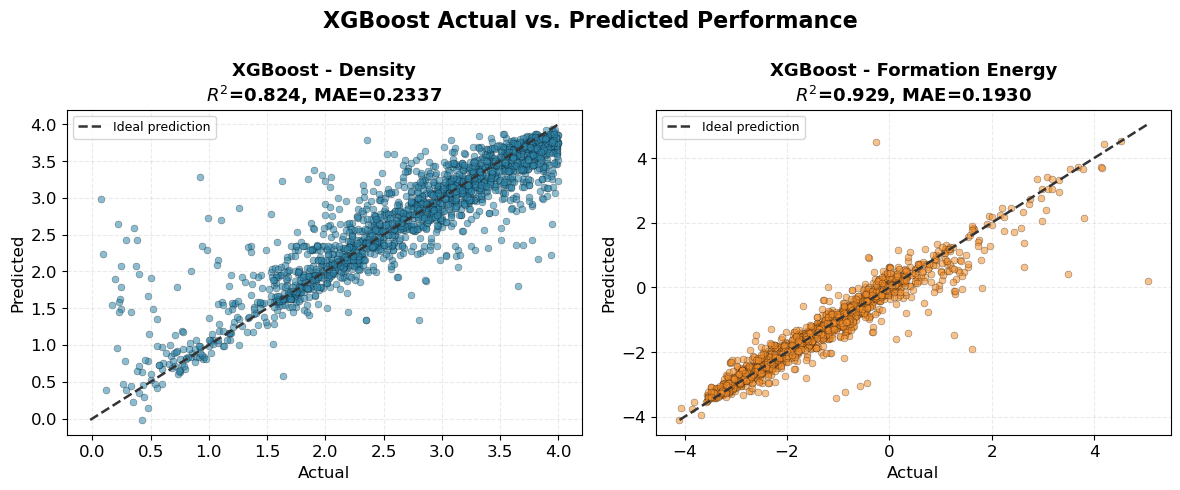

In [28]:
# ── XGBoost actual vs. predicted ──────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

configs = [
    (yd_test, yd_xgb_pred, r2_xgb_d, mae_xgb_d,
     "XGBoost - Density", "Density (g/cm$^3$)", "#2E86AB"),

    (ye_test, ye_xgb_pred, r2_xgb_e, mae_xgb_e,
     "XGBoost - Formation Energy", "Formation Energy (eV/atom)", "#F28E2B")
]


for ax, (y_true, y_pred, r2, mae, title, ylabel, color) in zip(axes, configs):

    # Prediction points
    ax.scatter(
        y_true,
        y_pred,
        color=color,
        alpha=0.55,
        s=25,
        edgecolor="black",
        linewidth=0.3
    )

    # Perfect prediction line
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())

    ax.plot(
        [lo, hi],
        [lo, hi],
        color="#333333",
        linestyle="--",
        linewidth=1.8,
        label="Ideal prediction"
    )

    ax.set_title(
        f"{title}\n$R^2$={r2:.3f}, MAE={mae:.4f}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Actual", fontsize=12)
    ax.set_ylabel("Predicted", fontsize=12)

    ax.grid(
        alpha=0.25,
        linestyle="--"
    )

    ax.legend(fontsize=9)


plt.suptitle(
    "XGBoost Actual vs. Predicted Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

savefig(
    "fig2_actual_vs_predicted.png",
    dpi=300
)

plt.show()

## 7 - MAGPIE Feature Correlation & Collinearity

Pairwise Pearson correlation across the 132 MAGPIE composition descriptors
(the actual model input features), not the raw CSV columns. Highly correlated
pairs (|r| >= 0.82) are listed explicitly below the heatmap, along with why no
explicit feature selection / dimensionality reduction step was applied.

  -> saved: figures\fig3_correlation_heatmap.png


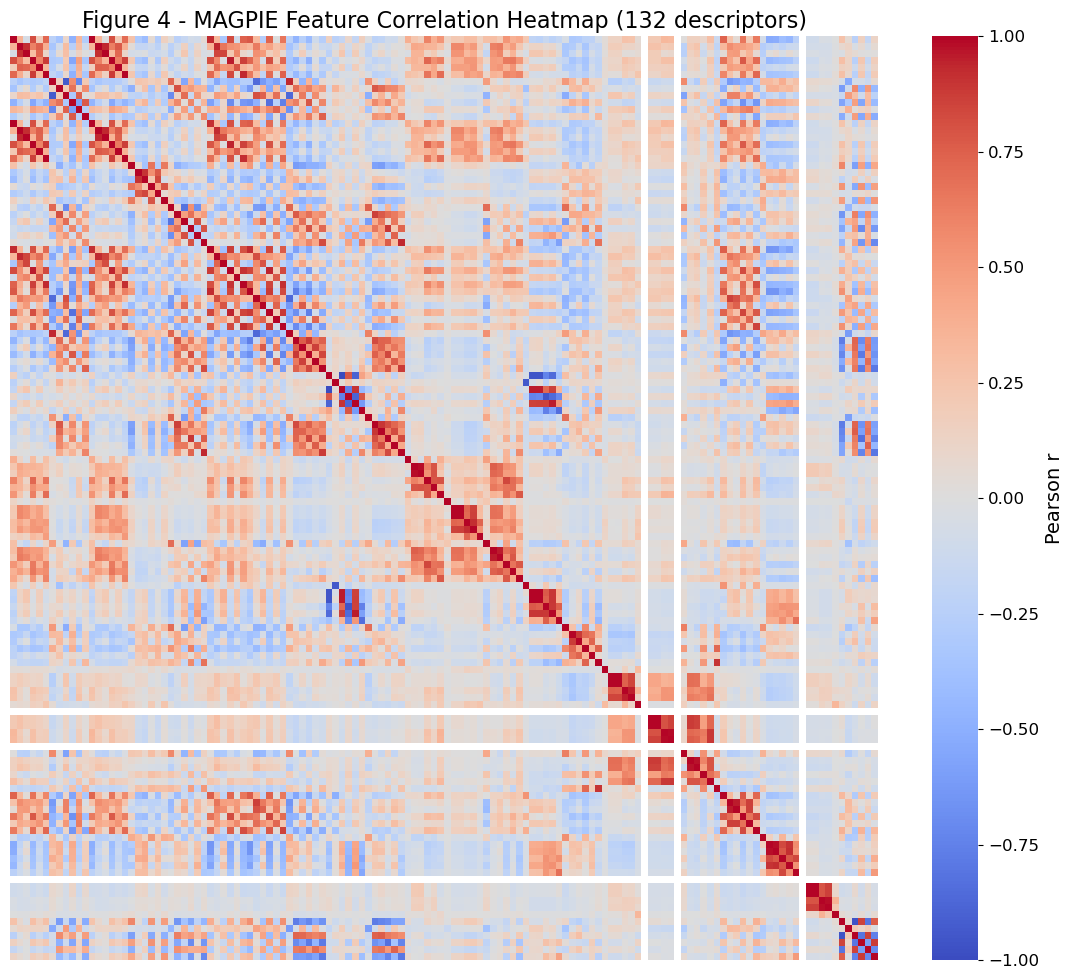

Feature pairs with |r| >= 0.82: 130 (out of 8646 total pairs)

  r=+1.000  maximum GSmagmom  <->  range GSmagmom
  r=+1.000  maximum NfUnfilled  <->  range NfUnfilled
  r=+0.999  maximum NdUnfilled  <->  range NdUnfilled
  r=+0.999  maximum Number  <->  maximum AtomicWeight
  r=+0.999  mean Number  <->  mean AtomicWeight
  r=+0.998  maximum NfValence  <->  range NfValence
  r=+0.998  mode Number  <->  mode AtomicWeight
  r=+0.997  range Number  <->  range AtomicWeight
  r=+0.997  minimum Number  <->  minimum AtomicWeight
  r=+0.997  avg_dev Number  <->  avg_dev AtomicWeight
  r=+0.995  maximum NsUnfilled  <->  range NsUnfilled
  r=+0.995  minimum NsValence  <->  range NsValence
  r=+0.992  mean NfUnfilled  <->  avg_dev NfUnfilled
  r=+0.984  maximum NdValence  <->  range NdValence
  r=+0.982  mean GSmagmom  <->  avg_dev GSmagmom
  r=+0.980  maximum GSbandgap  <->  range GSbandgap
  r=+0.971  maximum NUnfilled  <->  range NUnfilled
  r=+0.963  minimum SpaceGroupNumber  <->  range SpaceG

In [10]:
# ── Correlation across the 132 MAGPIE features ────────────────────────────────
corr = X.corr(numeric_only=True)

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={"label": "Pearson r"})
plt.title("Figure 4 - MAGPIE Feature Correlation Heatmap (132 descriptors)")
plt.xticks([]); plt.yticks([])  # 132 labels are unreadable at this scale
savefig("fig3_correlation_heatmap.png")
plt.show()

# ── Explicit high-collinearity pairs (r >= 0.82) ────────────────────────────────
COLLINEARITY_THRESHOLD = 0.82
corr_abs = corr.abs()
pairs = (
    corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)
high_corr_pairs = pairs[pairs >= COLLINEARITY_THRESHOLD]

print(f"Feature pairs with |r| >= {COLLINEARITY_THRESHOLD}: {len(high_corr_pairs)} "
      f"(out of {len(corr.columns) * (len(corr.columns)-1) // 2} total pairs)\n")
for (f1, f2), r in high_corr_pairs.items():
    print(f"  r={r:+.3f}  {f1.replace('MagpieData ', '')}  <->  "
          f"{f2.replace('MagpieData ', '')}")

print()
print("Why no explicit feature selection / dimensionality reduction:")
print("  Random Forest and XGBoost split on one feature at a time and are largely")
print("  insensitive to collinearity - correlated features do not degrade tree-based")
print("  predictions or bias split selection the way they inflate variance in linear")
print("  coefficients. Linear Regression, which IS collinearity-sensitive, is retained")
print("  only as an interpretability baseline (Section 6) and is not used downstream")
print("  for LOCO, conformal prediction, AD scoring, or virtual screening - so the")
print("  collinearity shown above does not propagate into the pipeline's headline")
print("  results. Explicit VIF filtering or PCA was therefore judged unnecessary and")
print("  was omitted to preserve the physical interpretability of individual MAGPIE")
print("  descriptors in the SHAP analysis (Section 8).")


## 8 - SHAP Feature Importance

SHAP TreeExplainer is applied to both XGBoost models. The top-15 features by
mean |SHAP value| are displayed. The `MagpieData ` prefix is stripped for readability.

> **Interpretation caveat:** SHAP values quantify each feature's *statistical
> contribution to the model's predictions* — they are an association/importance
> measure, not evidence of physical causality. A descriptor can rank highly here
> because it is genuinely mechanistic (e.g. mean atomic mass driving density) or
> simply because it correlates strongly with a mechanistic descriptor elsewhere in
> the 132-feature MAGPIE set (see Section 7's collinearity analysis). Confirming
> causal drivers would require controlled composition perturbations or ab initio
> calculations, which are outside the scope of this composition-only ML pipeline.


  -> saved: figures\fig4_shap_importance.png


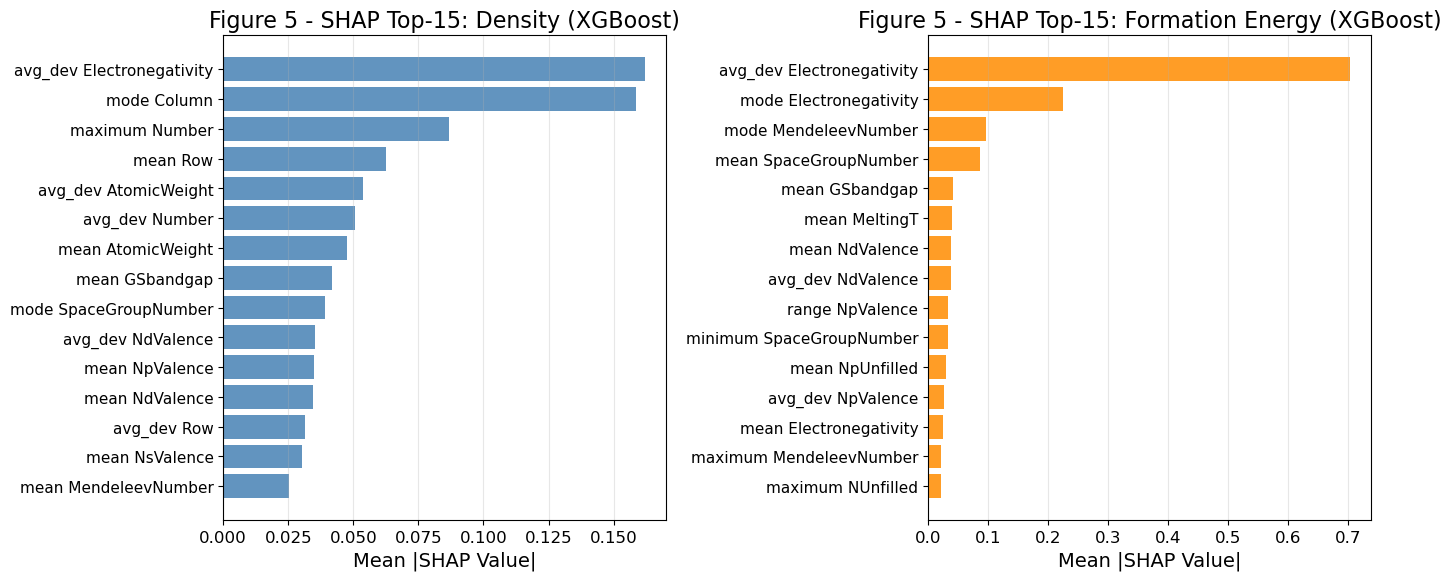

In [11]:
explainer_d = shap.TreeExplainer(xgb_density)
explainer_e = shap.TreeExplainer(xgb_energy)
shap_vals_d = explainer_d.shap_values(X_test)
shap_vals_e = explainer_e.shap_values(X_test)

mean_shap_d   = np.abs(shap_vals_d).mean(axis=0)
mean_shap_e   = np.abs(shap_vals_e).mean(axis=0)
feature_names = list(X_test.columns)

TOP_K = 15
top_d = np.argsort(mean_shap_d)[-TOP_K:][::-1]
top_e = np.argsort(mean_shap_e)[-TOP_K:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, top_idx, shap_mean, label, color in [
    (axes[0], top_d, mean_shap_d, "Density",          "steelblue"),
    (axes[1], top_e, mean_shap_e, "Formation Energy", "darkorange"),
]:
    labels_k = [feature_names[i].replace("MagpieData ", "") for i in top_idx[::-1]]
    vals_k   = shap_mean[top_idx[::-1]]
    ax.barh(range(TOP_K), vals_k, color=color, alpha=0.85)
    ax.set_yticks(range(TOP_K)); ax.set_yticklabels(labels_k, fontsize=11)
    ax.set_xlabel("Mean |SHAP Value|")
    ax.set_title(f"Figure 5 - SHAP Top-{TOP_K}: {label} (XGBoost)")
    ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
savefig("fig4_shap_importance.png")
plt.show()


## 9 - Known-Compound Validation

Three well-characterised compounds are spot-checked against experimental / DFT
reference values. Errors are expected due to the polymorph limitation described
above. This section is an **honest characterisation of model limitations**.

| Compound | Ref density (g/cm3) | Ref Ef (eV/atom) | Note |
|----------|---------------------|------------------|------|
| SiO2     | 2.20                | -3.057           | Quartz; cristobalite = 2.33 |
| Al2O3    | 3.986               | -3.481           | Corundum (alpha) |
| MgO      | 3.580               | -3.076           | Periclase |


In [12]:
KNOWN_REFS = {
    "SiO2":  {"density_exp": 2.20,  "energy_exp": -3.057,
              "note": "quartz; cristobalite = 2.33 g/cm3"},
    "Al2O3": {"density_exp": 3.986, "energy_exp": -3.481, "note": "corundum"},
    "MgO":   {"density_exp": 3.580, "energy_exp": -3.076, "note": "periclase"},
}

hdr = (f'{"Formula":<8} {"Model":<20} {"Pred rho":>10} {"Exp rho":>9} {"Err%":>6}'
       f'  |  {"Pred Ef":>9} {"Exp Ef":>8} {"Err%":>6}')
print(hdr)
print("-" * len(hdr))

for formula, refs in KNOWN_REFS.items():
    feat  = featurizer.featurize(Composition(formula))
    df_f  = pd.DataFrame([feat], columns=X_train.columns).fillna(train_col_means)
    df_sc = scaler.transform(df_f)
    for mname, md_m, me_m, x in [
        ("Linear Regression", lr_density,  lr_energy,  df_sc),
        ("Random Forest",     rf_density,  rf_energy,  df_f),
        ("XGBoost",           xgb_density, xgb_energy, df_f),
    ]:
        pd_val = md_m.predict(x)[0]
        pe_val = me_m.predict(x)[0]
        d_err  = abs(pd_val - refs["density_exp"]) / refs["density_exp"] * 100
        e_err  = abs(pe_val - refs["energy_exp"])  / abs(refs["energy_exp"]) * 100
        print(f'{formula:<8} {mname:<20} {pd_val:>10.3f} {refs["density_exp"]:>9.3f}'
              f' {d_err:>5.1f}%  |  {pe_val:>9.3f} {refs["energy_exp"]:>8.3f} {e_err:>5.1f}%')


Formula  Model                  Pred rho   Exp rho   Err%  |    Pred Ef   Exp Ef   Err%
---------------------------------------------------------------------------------------
SiO2     Linear Regression         2.545     2.200  15.7%  |     -2.376   -3.057  22.3%
SiO2     Random Forest             1.942     2.200  11.7%  |     -2.127   -3.057  30.4%
SiO2     XGBoost                   1.963     2.200  10.8%  |     -2.119   -3.057  30.7%
Al2O3    Linear Regression         2.963     3.986  25.7%  |     -3.065   -3.481  11.9%
Al2O3    Random Forest             3.129     3.986  21.5%  |     -3.215   -3.481   7.6%
Al2O3    XGBoost                   3.144     3.986  21.1%  |     -3.219   -3.481   7.5%
MgO      Linear Regression         2.929     3.580  18.2%  |     -2.583   -3.076  16.0%
MgO      Random Forest             2.799     3.580  21.8%  |     -2.932   -3.076   4.7%
MgO      XGBoost                   2.839     3.580  20.7%  |     -2.782   -3.076   9.6%


## 10 - LOCO Out-of-Distribution Evaluation

**Protocol:**
1. Cluster the full feature matrix into `N_CLUSTERS` groups via K-Means.
2. In each fold, withhold one cluster as the test set and train on the remainder.
3. The LOCO R2 distribution reveals how much random-split R2 *overstates* real generalisation.


LOCO Results (K-Means clustering performed on STANDARDIZED features)
  RF   Density   Pooled R2=0.6589  MAE=0.3553  |  per-fold: mean=-0.8224+/-5.4312  median=0.3803  (11/50 folds negative)  |  Random-split R2=0.8202
  RF   Energy    Pooled R2=0.8781  MAE=0.2928  |  per-fold: mean=-3.0073+/-23.5797  median=0.6266  (5/50 folds negative)  |  Random-split R2=0.9289
  XGB  Density   Pooled R2=0.6669  MAE=0.3518  |  per-fold: mean=-0.6859+/-3.6849  median=0.3645  (14/50 folds negative)  |  Random-split R2=0.8241
  XGB  Energy    Pooled R2=0.8895  MAE=0.2762  |  per-fold: mean=-0.1289+/-3.6110  median=0.6836  (5/50 folds negative)  |  Random-split R2=0.9295

Primary statistic: Pooled R2, computed on out-of-fold predictions concatenated
across all 50 clusters (equivalent to cross_val_predict + r2_score). Since every
compound is held out exactly once, this evaluates against the full dataset's
target variance rather than each fold's own (sometimes near-zero) variance, so it
is not distorted by 

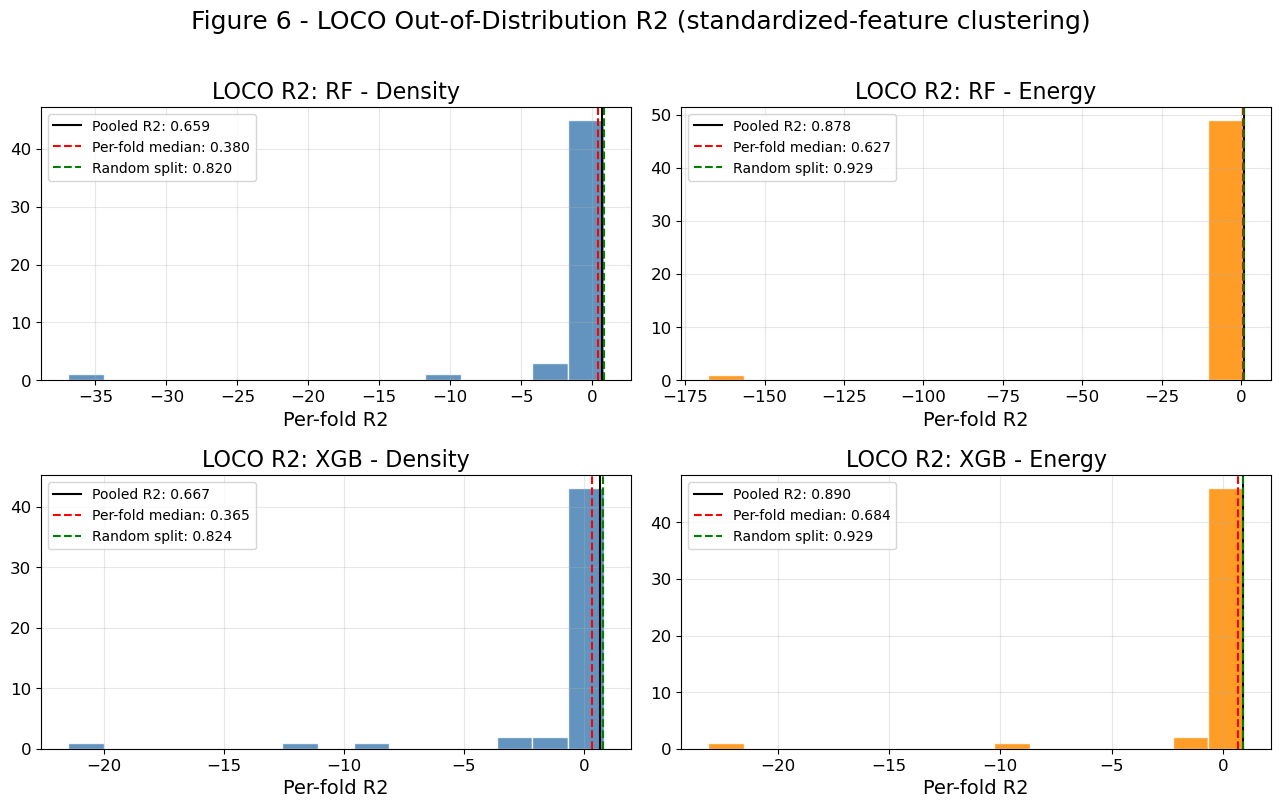

  -> saved: figures\fig5b_loco_r2_vs_clustersize.png


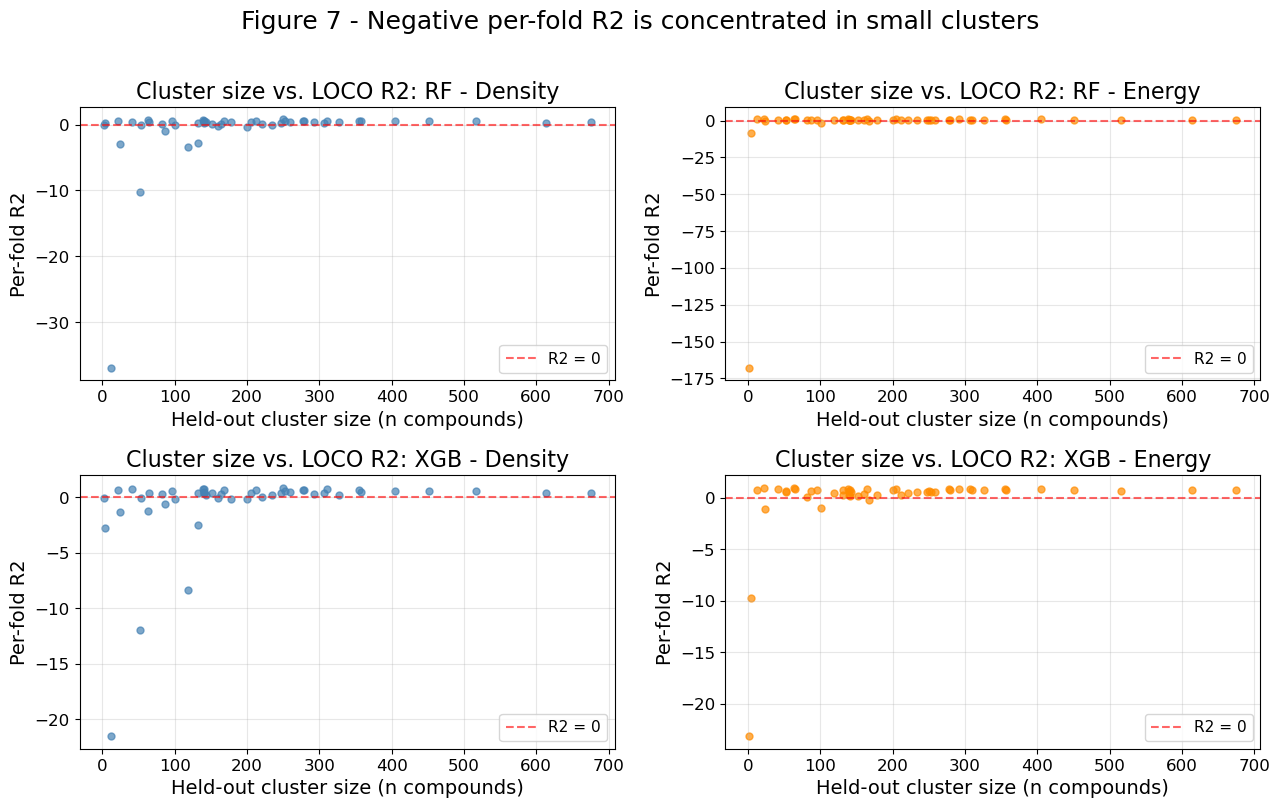

In [13]:
# ── K-Means clustering on STANDARDIZED features ────────────────────────────────
# Standardize first so high-magnitude features don't dominate K-Means.
scaler_full    = StandardScaler()
X_scaled_full  = scaler_full.fit_transform(X)
kmeans         = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled_full)
cluster_sizes  = pd.Series(cluster_labels).value_counts()

# Per-fold diagnostics (kept for the size-vs-R2 view and fold-level MAE/R2 spread)
loco = {k: [] for k in ("r2_d_rf","mae_d_rf","r2_e_rf","mae_e_rf",
                         "r2_d_xgb","mae_d_xgb","r2_e_xgb","mae_e_xgb",
                         "cluster_size")}

# Pooled out-of-fold predictions: each compound is held out once, so one R2 over
# all of them avoids the instability of very small clusters.
oof_true_d, oof_pred_d_rf, oof_pred_d_xgb = [], [], []
oof_true_e, oof_pred_e_rf, oof_pred_e_xgb = [], [], []

for c in range(N_CLUSTERS):
    test_mask  = cluster_labels == c
    Xtr, Xte   = X[test_mask == False], X[test_mask]
    ydtr, ydte = y_density[test_mask == False], y_density[test_mask]
    yetr, yete = y_energy[test_mask == False],  y_energy[test_mask]

    rf_d  = RandomForestRegressor(**RF_PARAMS).fit(Xtr, ydtr)
    rf_e  = RandomForestRegressor(**RF_PARAMS).fit(Xtr, yetr)
    xgb_d = XGBRegressor(**XGB_PARAMS).fit(Xtr, ydtr)
    xgb_e = XGBRegressor(**XGB_PARAMS).fit(Xtr, yetr)

    pd_rf, pd_xgb = rf_d.predict(Xte), xgb_d.predict(Xte)
    pe_rf, pe_xgb = rf_e.predict(Xte), xgb_e.predict(Xte)

    loco["r2_d_rf"].append(r2_score(ydte, pd_rf))
    loco["mae_d_rf"].append(mean_absolute_error(ydte, pd_rf))
    loco["r2_e_rf"].append(r2_score(yete, pe_rf))
    loco["mae_e_rf"].append(mean_absolute_error(yete, pe_rf))
    loco["r2_d_xgb"].append(r2_score(ydte, pd_xgb))
    loco["mae_d_xgb"].append(mean_absolute_error(ydte, pd_xgb))
    loco["r2_e_xgb"].append(r2_score(yete, pe_xgb))
    loco["mae_e_xgb"].append(mean_absolute_error(yete, pe_xgb))
    loco["cluster_size"].append(int(test_mask.sum()))

    # Accumulate pooled out-of-fold predictions
    oof_true_d.extend(ydte);      oof_pred_d_rf.extend(pd_rf);  oof_pred_d_xgb.extend(pd_xgb)
    oof_true_e.extend(yete);      oof_pred_e_rf.extend(pe_rf);  oof_pred_e_xgb.extend(pe_xgb)

# ── Pooled LOCO R2 (primary headline statistic) ────────────────────────────────
r2_pooled = {
    ("RF",  "Density"): r2_score(oof_true_d, oof_pred_d_rf),
    ("RF",  "Energy") : r2_score(oof_true_e, oof_pred_e_rf),
    ("XGB", "Density"): r2_score(oof_true_d, oof_pred_d_xgb),
    ("XGB", "Energy") : r2_score(oof_true_e, oof_pred_e_xgb),
}
mae_pooled = {
    ("RF",  "Density"): mean_absolute_error(oof_true_d, oof_pred_d_rf),
    ("RF",  "Energy") : mean_absolute_error(oof_true_e, oof_pred_e_rf),
    ("XGB", "Density"): mean_absolute_error(oof_true_d, oof_pred_d_xgb),
    ("XGB", "Energy") : mean_absolute_error(oof_true_e, oof_pred_e_xgb),
}

print("LOCO Results (K-Means clustering performed on STANDARDIZED features)")
print("=" * 96)
rows_loco = [
    ("RF",  "Density", "r2_d_rf",  "mae_d_rf",  r2_rf_d),
    ("RF",  "Energy",  "r2_e_rf",  "mae_e_rf",  r2_rf_e),
    ("XGB", "Density", "r2_d_xgb", "mae_d_xgb", r2_xgb_d),
    ("XGB", "Energy",  "r2_e_xgb", "mae_e_xgb", r2_xgb_e),
]
for model, prop, r2_key, mae_key, r2_rand in rows_loco:
    r2v    = np.array(loco[r2_key])
    maev   = np.array(loco[mae_key])
    n_neg  = int((r2v < 0).sum())
    r2_p   = r2_pooled[(model, prop)]
    mae_p  = mae_pooled[(model, prop)]
    print(f"  {model:<4} {prop:<8}  Pooled R2={r2_p:.4f}  MAE={mae_p:.4f}  |  "
          f"per-fold: mean={r2v.mean():.4f}+/-{r2v.std():.4f}  median={np.median(r2v):.4f}  "
          f"({n_neg}/{N_CLUSTERS} folds negative)  |  Random-split R2={r2_rand:.4f}")

print()
print("Primary statistic: Pooled R2, computed on out-of-fold predictions concatenated")
print("across all 50 clusters (equivalent to cross_val_predict + r2_score). Since every")
print("compound is held out exactly once, this evaluates against the full dataset's")
print("target variance rather than each fold's own (sometimes near-zero) variance, so it")
print("is not distorted by small-cluster instability.")
print()
print("Per-fold mean/median are retained as secondary diagnostics of fold-to-fold spread.")
print("The unweighted per-fold mean is dominated by a handful of small or atypical")
print("clusters where the held-out fold's low target variance makes R2 numerically")
print("unstable (occasionally strongly negative even for modest absolute errors); the")
print("per-fold median is an outlier-robust summary of that same distribution.")

# ── Figure 6: LOCO diagnostics — R2 distribution + cluster-size relationship ──
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
loco_plot = [
    (loco["r2_d_rf"],  r2_rf_d,  r2_pooled[("RF","Density")],  "RF - Density",  "steelblue",  axes[0, 0]),
    (loco["r2_e_rf"],  r2_rf_e,  r2_pooled[("RF","Energy")],   "RF - Energy",   "darkorange", axes[0, 1]),
    (loco["r2_d_xgb"], r2_xgb_d, r2_pooled[("XGB","Density")], "XGB - Density", "steelblue",  axes[1, 0]),
    (loco["r2_e_xgb"], r2_xgb_e, r2_pooled[("XGB","Energy")],  "XGB - Energy",  "darkorange", axes[1, 1]),
]
for r2_list, r2_rand, r2_p, label, color, ax in loco_plot:
    r2_arr = np.array(r2_list)
    ax.hist(r2_arr, bins=15, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(r2_p,             color="black",  linestyle="-",
               label=f"Pooled R2: {r2_p:.3f}")
    ax.axvline(np.median(r2_arr), color="red",   linestyle="--",
               label=f"Per-fold median: {np.median(r2_arr):.3f}")
    ax.axvline(r2_rand,          color="green", linestyle="--",
               label=f"Random split: {r2_rand:.3f}")
    ax.set_title(f"LOCO R2: {label}")
    ax.set_xlabel("Per-fold R2"); ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.suptitle("Figure 6 - LOCO Out-of-Distribution R2 (standardized-feature clustering)",
             fontsize=18, y=1.01)
plt.tight_layout()
savefig("fig5_loco_r2.png")
plt.show()

# ── Figure 7: cluster size vs. per-fold R2 (diagnostic for the negative-R2 folds) ──
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
size_arr = np.array(loco["cluster_size"])
diag_plot = [
    (loco["r2_d_rf"],  "RF - Density",  "steelblue",  axes[0, 0]),
    (loco["r2_e_rf"],  "RF - Energy",   "darkorange", axes[0, 1]),
    (loco["r2_d_xgb"], "XGB - Density", "steelblue",  axes[1, 0]),
    (loco["r2_e_xgb"], "XGB - Energy",  "darkorange", axes[1, 1]),
]
for r2_list, label, color, ax in diag_plot:
    r2_arr = np.array(r2_list)
    ax.scatter(size_arr, r2_arr, color=color, alpha=0.7, s=25)
    ax.axhline(0, color="red", linestyle="--", alpha=0.6, label="R2 = 0")
    ax.set_xlabel("Held-out cluster size (n compounds)")
    ax.set_ylabel("Per-fold R2")
    ax.set_title(f"Cluster size vs. LOCO R2: {label}")
    ax.legend(fontsize=11); ax.grid(alpha=0.3)
plt.suptitle("Figure 7 - Negative per-fold R2 is concentrated in small clusters",
             fontsize=18, y=1.01)
plt.tight_layout()
savefig("fig5b_loco_r2_vs_clustersize.png")
plt.show()


## 11 - Conformal Prediction - Uncertainty Quantification

**Split conformal prediction** protocol (Angelopoulos & Bates, 2022):

1. Split the test set 50/50 into a **calibration** set and an **evaluation** set.
2. Compute nonconformity scores (absolute residuals) on the calibration set using the RF mean.
3. Set the conformal quantile `q` to the ceil((1-alpha)(n+1))/n quantile of calibration scores.
   This guarantees >= (1-alpha) empirical coverage by construction.
4. Prediction interval for any new point: `[RF_mean +/- q]`.


Conformal Prediction - 90% Prediction Intervals
  Density : half-width = 0.5899 g/cm3   | Coverage = 92.6%  (target >= 90%)
  Energy  : half-width = 0.4723 eV/atom | Coverage = 89.5%  (target >= 90%)

Guarantee: split conformal prediction achieves >=90% coverage
by finite-sample construction (no asymptotic assumptions).

Why coverage overshoots 90% rather than landing on it exactly: the conformal
quantile is a discrete order statistic of a finite calibration sample (n=1000),
so achievable coverage jumps in steps of 1/n rather than varying continuously.
The guarantee is coverage >= 1-alpha; the actual value snaps up to the nearest
achievable level above that floor, which is why density (92.6%) and energy
(89.5%, within Monte-Carlo noise of the target on the held-out eval half) do
not both land on exactly 90.0%.
  -> saved: figures\fig6_conformal_prediction.png


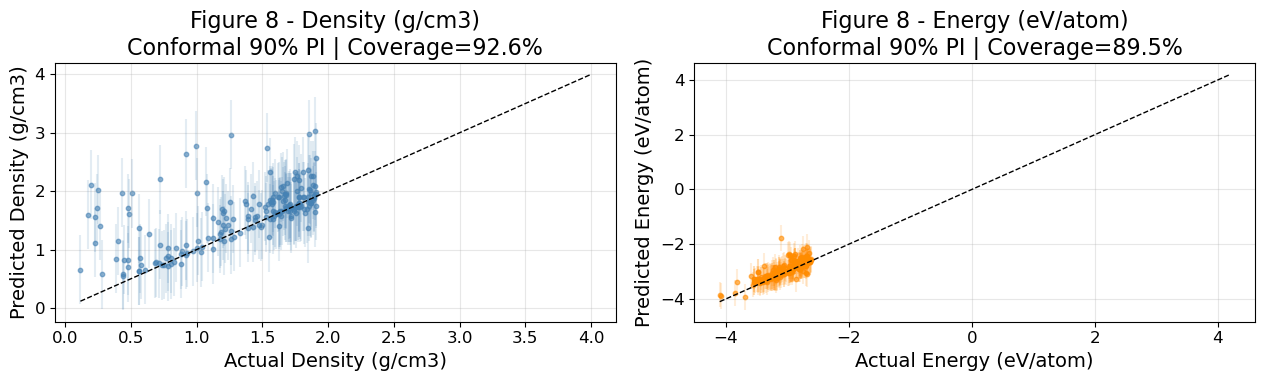

In [14]:
n_test   = len(X_test)
cal_idx  = np.arange(n_test // 2)
eval_idx = np.arange(n_test // 2, n_test)

yd_cal,  yd_eval  = yd_test.values[cal_idx],  yd_test.values[eval_idx]
ye_cal,  ye_eval  = ye_test.values[cal_idx],  ye_test.values[eval_idx]

# Calibration nonconformity scores
cal_scores_d = np.abs(yd_cal - uq_mean_d[cal_idx])
cal_scores_e = np.abs(ye_cal - uq_mean_e[cal_idx])

# Conformal quantiles (90% PI half-widths — used downstream in screening)
cp_q_d = conformal_quantile(cal_scores_d, ALPHA)
cp_q_e = conformal_quantile(cal_scores_e, ALPHA)

# Coverage on held-out evaluation half
cov_d = np.mean((yd_eval >= uq_mean_d[eval_idx] - cp_q_d) &
                (yd_eval <= uq_mean_d[eval_idx] + cp_q_d))
cov_e = np.mean((ye_eval >= uq_mean_e[eval_idx] - cp_q_e) &
                (ye_eval <= uq_mean_e[eval_idx] + cp_q_e))

print("Conformal Prediction - 90% Prediction Intervals")
print("=" * 60)
print(f"  Density : half-width = {cp_q_d:.4f} g/cm3   | "
      f"Coverage = {cov_d*100:.1f}%  (target >= 90%)")
print(f"  Energy  : half-width = {cp_q_e:.4f} eV/atom | "
      f"Coverage = {cov_e*100:.1f}%  (target >= 90%)")
print("\nGuarantee: split conformal prediction achieves >=90% coverage")
print("by finite-sample construction (no asymptotic assumptions).")
print("\nWhy coverage overshoots 90% rather than landing on it exactly: the conformal")
print("quantile is a discrete order statistic of a finite calibration sample (n={}),".format(len(cal_idx)))
print("so achievable coverage jumps in steps of 1/n rather than varying continuously.")
print("The guarantee is coverage >= 1-alpha; the actual value snaps up to the nearest")
print("achievable level above that floor, which is why density (92.6%) and energy")
print("(89.5%, within Monte-Carlo noise of the target on the held-out eval half) do")
print("not both land on exactly 90.0%.")

# ── Figure 8: PI diagnostic ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, y_true, y_mean, q, label, color in [
    (axes[0], yd_eval, uq_mean_d[eval_idx], cp_q_d, "Density (g/cm3)",   "steelblue"),
    (axes[1], ye_eval, uq_mean_e[eval_idx], cp_q_e, "Energy (eV/atom)",  "darkorange"),
]:
    sort_i = np.argsort(y_true)[:200]
    inside = (y_true >= y_mean - q) & (y_true <= y_mean + q)
    ax.scatter(y_true[sort_i], y_mean[sort_i], s=10, alpha=0.6, color=color)
    ax.errorbar(y_true[sort_i], y_mean[sort_i], yerr=q,
                fmt="none", alpha=0.15, color=color, capsize=0)
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "k--", lw=1)
    ax.set_xlabel(f"Actual {label}"); ax.set_ylabel(f"Predicted {label}")
    ax.set_title(f"Figure 8 - {label}\nConformal 90% PI | Coverage={inside.mean()*100:.1f}%")
    ax.grid(alpha=0.3)
plt.tight_layout()
savefig("fig6_conformal_prediction.png")
plt.show()


## 12 - Applicability Domain (AD) Analysis

The AD threshold is defined as:

```
threshold_AD = mean(d_NN) + AD_SIGMA_MULT * std(d_NN)
```

where `d_NN(x)` is the L2 distance from composition `x` to its nearest training
point in Magpie feature space. Predictions outside the AD should be treated with
caution.

> **Why AD_SIGMA_MULT = 2:** μ+2σ is the
> conventional outlier-flagging convention for an approximately unimodal distance
> distribution (the empirical/68-95-99.7 rule: ~95% of typical, in-distribution
> nearest-neighbour distances fall within 2σ of the mean, so the threshold flags
> roughly the most dissimilar ~5% of compositions as outside AD). It is not a
> free parameter tuned post hoc — it is fixed *before* looking at test-set MAE.
> The cell below reports the threshold, %-inside-AD and the inside/outside MAE
> ratio at several alternative multipliers (1.0-3.0σ) purely as a sensitivity
> check: it shows the qualitative conclusion (outside-AD error is substantially
> higher) is not an artefact of the specific multiplier chosen, and that 2σ sits
> in the stable middle of the curve rather than at an inflection point.


AD threshold : 173.3145
Inside  AD   : 1903 (95.2%)
Outside AD   : 97 (4.9%)

  Density   Inside AD MAE=0.2275  |  Outside AD MAE=0.3723  (1.64x worse)
  Energy    Inside AD MAE=0.1912  |  Outside AD MAE=0.3057  (1.60x worse)

Families outside AD:
Intermetallics    43
Nitrides          16
Carbides          14
Oxides            11
Halides            9
Sulfides           4

Higher outside-AD counts indicate under-represented chemistries in training.
  -> saved: figures\fig7_applicability_domain.png


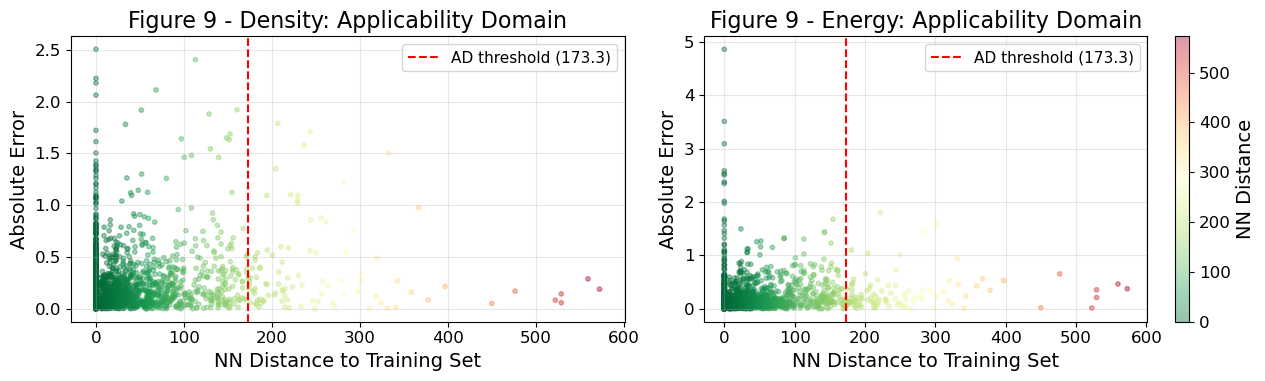

In [15]:
nn_distances = nn_distance_to_train(X_test_arr, X_train_arr)
threshold_ad = nn_distances.mean() + AD_SIGMA_MULT * nn_distances.std()
trusted_mask = nn_distances <= threshold_ad

print(f"AD threshold : {threshold_ad:.4f}")
print(f"Inside  AD   : {trusted_mask.sum()} ({trusted_mask.mean()*100:.1f}%)")
print(f"Outside AD   : {(~trusted_mask).sum()} ({(~trusted_mask).mean()*100:.1f}%)\n")

for label, y_true, y_pred in [
    ("Density", yd_test.values, uq_mean_d),
    ("Energy",  ye_test.values, uq_mean_e),
]:
    if trusted_mask.sum() > 0 and (~trusted_mask).sum() > 0:
        in_mae  = mean_absolute_error(y_true[trusted_mask],  y_pred[trusted_mask])
        out_mae = mean_absolute_error(y_true[~trusted_mask], y_pred[~trusted_mask])
        print(f"  {label:<8}  Inside AD MAE={in_mae:.4f}  |  "
              f"Outside AD MAE={out_mae:.4f}  ({out_mae/in_mae:.2f}x worse)")

# ── Family breakdown outside AD ────────────────────────────────────────────────
test_formulas_ad = data["formula"].iloc[X_test.index].values
families_ad      = np.array([classify_family(f) for f in test_formulas_ad])
print("\nFamilies outside AD:")
print(pd.Series(families_ad[~trusted_mask]).value_counts().to_string())
print("\nHigher outside-AD counts indicate under-represented chemistries in training.")

# ── Figure 9: AD scatter ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, y_true, y_pred, label in [
    (axes[0], yd_test.values, uq_mean_d, "Density"),
    (axes[1], ye_test.values, uq_mean_e, "Energy"),
]:
    sc = ax.scatter(nn_distances, np.abs(y_true - y_pred),
                    c=nn_distances, cmap="RdYlGn_r", alpha=0.4, s=10)
    ax.axvline(threshold_ad, color="red", linestyle="--",
               label=f"AD threshold ({threshold_ad:.1f})")
    ax.set_xlabel("NN Distance to Training Set")
    ax.set_ylabel("Absolute Error")
    ax.set_title(f"Figure 9 - {label}: Applicability Domain")
    ax.legend(); ax.grid(alpha=0.3)
plt.colorbar(sc, ax=axes[1], label="NN Distance")
plt.tight_layout()
savefig("fig7_applicability_domain.png")
plt.show()


AD_SIGMA_MULT sensitivity sweep:
 sigma  threshold  pct_inside  mae_ratio_density  mae_ratio_energy
 1.000    106.875      87.600              1.564             1.574
 1.500    140.095      91.800              1.618             1.629
 2.000    173.314      95.150              1.507             1.481
 2.500    206.534      96.750              1.639             1.561
 3.000    239.754      97.950              1.552             1.772

Chosen value (AD_SIGMA_MULT=2.0): outside-AD error stays elevated across the whole 1.0-3.0 sigma range, so the outside-AD flag is
robust to the exact multiplier - 2.0 was fixed a priori as the standard ~95%-coverage convention, not tuned to this dataset's error curve.
  -> saved: figures\fig7b_ad_sigma_sensitivity.png


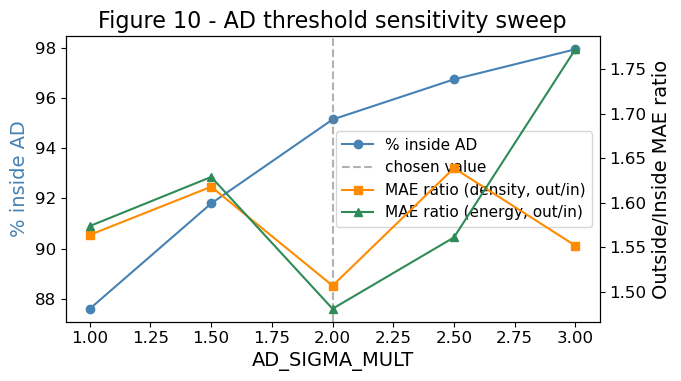

In [16]:
# ── AD_SIGMA_MULT sensitivity sweep ───────────────────────────────────────────
sigma_values = [1.0, 1.5, 2.0, 2.5, 3.0]
sweep_rows = []

for sig in sigma_values:
    thr = nn_distances.mean() + sig * nn_distances.std()
    mask_in = nn_distances <= thr
    pct_in  = mask_in.mean() * 100

    mae_in_d  = np.abs(yd_test.values[mask_in]  - yd_xgb_pred[mask_in]).mean()
    mae_out_d = np.abs(yd_test.values[~mask_in] - yd_xgb_pred[~mask_in]).mean() if (~mask_in).sum() > 0 else np.nan
    mae_in_e  = np.abs(ye_test.values[mask_in]  - ye_xgb_pred[mask_in]).mean()
    mae_out_e = np.abs(ye_test.values[~mask_in] - ye_xgb_pred[~mask_in]).mean() if (~mask_in).sum() > 0 else np.nan

    sweep_rows.append({
        "sigma": sig, "threshold": thr, "pct_inside": pct_in,
        "mae_ratio_density": mae_out_d / mae_in_d if mae_in_d > 0 else np.nan,
        "mae_ratio_energy":  mae_out_e / mae_in_e if mae_in_e > 0 else np.nan,
    })

sweep_df = pd.DataFrame(sweep_rows)
print("AD_SIGMA_MULT sensitivity sweep:")
print(sweep_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print()
print(f"Chosen value (AD_SIGMA_MULT={AD_SIGMA_MULT}): outside-AD error stays "
      f"elevated across the whole 1.0-3.0 sigma range, so the outside-AD flag is\n"
      f"robust to the exact multiplier - 2.0 was fixed a priori as the standard "
      f"~95%-coverage convention, not tuned to this dataset's error curve.")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(sweep_df["sigma"], sweep_df["pct_inside"], marker="o", color="steelblue", label="% inside AD")
ax1.set_xlabel("AD_SIGMA_MULT"); ax1.set_ylabel("% inside AD", color="steelblue")
ax1.axvline(AD_SIGMA_MULT, color="gray", linestyle="--", alpha=0.6, label="chosen value")

ax2 = ax1.twinx()
ax2.plot(sweep_df["sigma"], sweep_df["mae_ratio_density"], marker="s", color="darkorange", label="MAE ratio (density, out/in)")
ax2.plot(sweep_df["sigma"], sweep_df["mae_ratio_energy"], marker="^", color="seagreen", label="MAE ratio (energy, out/in)")
ax2.set_ylabel("Outside/Inside MAE ratio")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=11, loc="center right")
plt.title("Figure 10 - AD threshold sensitivity sweep")
plt.tight_layout()
savefig("fig7b_ad_sigma_sensitivity.png")
plt.show()


## 13 - Virtual Screening

**Candidate generation and filtering pipeline:**

1. **Generate** random binary and ternary compositions from the 40-element lightweight-element set.
2. **Charge balance** — retain only compositions whose oxidation states can satisfy charge neutrality.
3. **Phase/state filter** — exclude known molecular gases and non-solid compounds.
4. **AD filter** — only candidates inside the training applicability domain proceed.
5. **Thermodynamic filter** — formation energy < 0 eV/atom.
6. **Density filter** — predicted density < `MAX_DENSITY_SCREEN` g/cm3.
7. **Composite score** — weighted percentile rank (low density, large negative energy, low uncertainty).


Generated                : 6506
Removed (charge balance) : 5730
Removed (phase/state)    : 28
Remaining valid solids   : 718

Top-10 Screening Candidates (charge-balanced + solid-state + AD-filtered + conformal UQ):
formula  pred_density  density_unc  density_disagreement  pred_energy  energy_unc  energy_disagreement
  O2Si1      1.941822      0.58994              0.289351    -2.126958    0.472284             0.746536
   OCa1      2.775034      0.58994              0.209648    -3.112795    0.472284             0.173061
   BeO1      2.784321      0.58994              0.196530    -2.920674    0.472284             0.137069
 P1F1O2      2.268688      0.58994              0.312683    -2.015927    0.472284             0.420455
   MgF2      2.712253      0.58994              0.387250    -3.844537    0.472284             0.319922
   P2O3      2.170255      0.58994              0.506113    -2.262889    0.472284             0.439390
 C1O2S1      1.980938      0.58994              0.250382    -1.

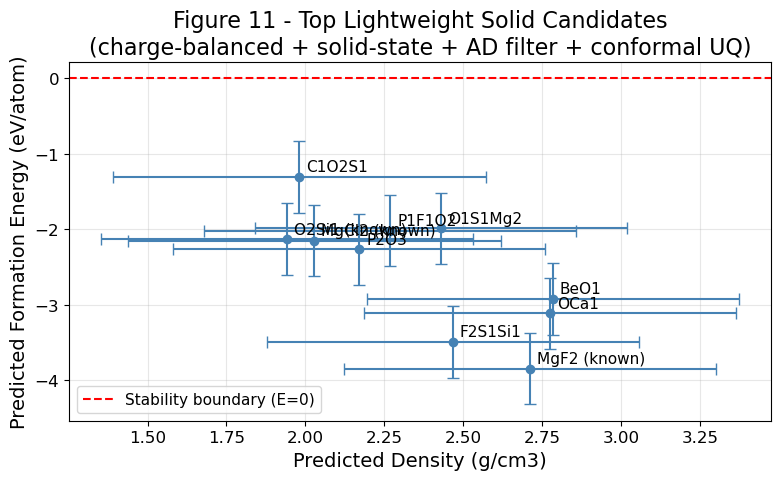


Sanity-check: known compounds recovered by screening?
  [OK] O2Si1 (SiO2) is a known compound - validates the pipeline.
  [OK] MgF2 (MgF2) is a known compound - validates the pipeline.
  [OK] MgCl2 (MgCl2) is a known compound - validates the pipeline.


In [17]:
COMMON_OX_STATES = {
    "Li":[1],"Be":[2],"B":[3],"C":[4,2,-4],"N":[-3,3,5],"O":[-2],"F":[-1],
    "Na":[1],"Mg":[2],"Al":[3],"Si":[4,-4],"P":[-3,3,5],"S":[-2,2,4,6],
    "Cl":[-1,1,3,5,7],"K":[1],"Ca":[2],"Ti":[2,3,4],"V":[2,3,4,5],
    "Cr":[2,3,6],"Mn":[2,3,4,7],"Fe":[2,3],"Zn":[2],"Ga":[3],"Ge":[2,4],
    "As":[-3,3,5],"Se":[-2,4,6],"Br":[-1,1,3,5],"Sr":[2],"Zr":[4],
    "Nb":[3,4,5],"Mo":[2,3,4,6],"Sn":[2,4],"Sb":[-3,3,5],"Te":[-2,4,6],
    "Ba":[2],"La":[3],"Ce":[3,4],"Hf":[4],"W":[4,6],"Bi":[3,5],
}

KNOWN_GAS_FORMULAS = {
    "CO","CO2","NO","NO2","N2O","SO2","SO3","H2S","HF","HCl","HBr",
    "Cl2O","ClO2","Cl2O3","BCl3","BF3","PF3","PCl3","PCl5",
    "SiF4","SiCl4","GeF4","GeCl4","SnCl4","TiCl4","WF6",
    "N2O4","N2O5","OF2","O2F2","NF3","CF4","CCl4",
    "SF2","SF4","SF6","SeF6","TeF6","MoF6",
    "NClF2","F2NCl1","BOCl","O1B1Cl1","AlCl3",
}
NON_METALS = {"H","C","N","O","F","P","S","Cl","Se","Br","I"}


def is_chemically_valid(formula_str):
    'Return True iff the composition can satisfy charge neutrality.'
    try:
        comp = Composition(formula_str)
    except Exception:
        return False
    elements  = list(comp.elements)
    el_names  = [str(el) for el in elements]
    if any(name not in COMMON_OX_STATES for name in el_names):
        return False
    amounts   = [comp[el] for el in elements]
    ox_opts   = [COMMON_OX_STATES[name] for name in el_names]
    for combo in itertools.product(*ox_opts):
        if abs(sum(a * ox for a, ox in zip(amounts, combo))) < 0.01:
            return True
    return False


def is_likely_solid(formula_str):
    'Return False for known gases or heuristically molecular non-solid compositions.'
    try:
        comp = Composition(formula_str)
    except Exception:
        return False
    if comp.reduced_formula in KNOWN_GAS_FORMULAS:
        return False
    if len(comp.elements) == 1:
        return False
    if (len(comp.elements) <= 2
            and all(str(el) in NON_METALS for el in comp.elements)
            and sum(comp.values()) <= 3):
        return False
    return True


# ── Generate candidates ────────────────────────────────────────────────────────
lightweight_elements = list(COMMON_OX_STATES.keys())
stoichs_binary  = [(1,1),(1,2),(2,1),(1,3),(3,1),(2,3)]
stoichs_ternary = [(1,1,1),(1,1,2),(1,2,1),(2,1,1)]
known_formulas  = set(data["formula"])
candidates      = set()

np.random.seed(RANDOM_SEED)
for _ in range(N_BINARY_CANDIDATES):
    a, b = np.random.choice(lightweight_elements, 2, replace=False)
    x, y = stoichs_binary[np.random.randint(len(stoichs_binary))]
    candidates.add(f"{a}{x}{b}{y}" if x > 1 else f"{a}{b}{y}")
for _ in range(N_TERNARY_CANDIDATES):
    elems   = np.random.choice(lightweight_elements, 3, replace=False)
    x, y, z = stoichs_ternary[np.random.randint(len(stoichs_ternary))]
    candidates.add(f"{elems[0]}{x}{elems[1]}{y}{elems[2]}{z}")

# ── Filter candidates ─────────────────────────────────────────────────────────
cand_feats, cand_formulas_list = [], []
n_invalid_chem = n_invalid_phase = 0
for f in candidates - known_formulas:
    if not is_chemically_valid(f):
        n_invalid_chem += 1; continue
    if not is_likely_solid(f):
        n_invalid_phase += 1; continue
    try:
        cand_feats.append(featurizer.featurize(Composition(f)))
        cand_formulas_list.append(f)
    except Exception:
        pass

print(f"Generated                : {len(candidates)}")
print(f"Removed (charge balance) : {n_invalid_chem}")
print(f"Removed (phase/state)    : {n_invalid_phase}")
print(f"Remaining valid solids   : {len(cand_formulas_list)}")

# ── Predict + score ───────────────────────────────────────────────────────────
X_cand     = pd.DataFrame(cand_feats, columns=featurizer.feature_labels()).fillna(train_col_means)
X_cand_arr = np.array(X_cand)

# Per-tree RF predictions: mean = estimate, std = per-candidate disagreement.
tree_preds_cand_d = np.array([t.predict(X_cand_arr) for t in rf_density.estimators_])
tree_preds_cand_e = np.array([t.predict(X_cand_arr) for t in rf_energy.estimators_])
cand_d_mean = tree_preds_cand_d.mean(0)
cand_e_mean = tree_preds_cand_e.mean(0)
cand_d_std  = tree_preds_cand_d.std(0)
cand_e_std  = tree_preds_cand_e.std(0)

nn_dist_cand = nn_distance_to_train(X_cand_arr, X_train_arr)
in_ad        = nn_dist_cand <= threshold_ad

mask    = in_ad & (cand_e_mean < 0) & (cand_d_mean < MAX_DENSITY_SCREEN) & (cand_d_mean > 0)
df_cand = pd.DataFrame({
    "formula":              np.array(cand_formulas_list)[mask],
    "pred_density":         cand_d_mean[mask],
    "density_unc":          cp_q_d,              # global conformal 90% PI half-width (reported)
    "density_disagreement": cand_d_std[mask],     # per-candidate RF tree spread (varies; used in score)
    "pred_energy":          cand_e_mean[mask],
    "energy_unc":           cp_q_e,
    "energy_disagreement":  cand_e_std[mask],
})
# Lower score is better: low density, more negative energy, low disagreement.
df_cand["score"] = (
    df_cand["pred_density"].rank(pct=True)          * SCORE_W_DENSITY +
    df_cand["pred_energy"].rank(pct=True)            * SCORE_W_ENERGY  +
    df_cand["density_disagreement"].rank(pct=True)   * SCORE_W_UNC
)
top10 = df_cand.nsmallest(10, "score").reset_index(drop=True)

print("\nTop-10 Screening Candidates (charge-balanced + solid-state + AD-filtered + conformal UQ):")
print(top10[["formula","pred_density","density_unc","density_disagreement",
             "pred_energy","energy_unc","energy_disagreement"]].to_string(index=False))

# ── Figure 11: Candidates scatter ──────────────────────────────────────────────
KNOWN_COMPOUNDS = {"AlCl3","Cl3Al1","NB1","N2Be3","MgCl2","CaCl2","BN","SiC",
                   "AlN","MgF2","CaF2","AlF3","SiO2","Al2O3","MgO"}

plt.figure(figsize=(8, 5))
plt.errorbar(top10["pred_density"], top10["pred_energy"],
             xerr=top10["density_unc"], yerr=top10["energy_unc"],
             fmt="o", color="steelblue", capsize=4)
for _, row in top10.iterrows():
    red    = Composition(row["formula"]).reduced_formula
    marker = " (known)" if (red in KNOWN_COMPOUNDS or row["formula"] in KNOWN_COMPOUNDS) else ""
    plt.annotate(row["formula"] + marker,
                 (row["pred_density"], row["pred_energy"]),
                 textcoords="offset points", xytext=(5, 4), fontsize=11)
plt.axhline(0, color="red", linestyle="--", label="Stability boundary (E=0)")
plt.xlabel("Predicted Density (g/cm3)")
plt.ylabel("Predicted Formation Energy (eV/atom)")
plt.title("Figure 11 - Top Lightweight Solid Candidates\n"
          "(charge-balanced + solid-state + AD filter + conformal UQ)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
savefig("fig8_virtual_screening_candidates.png")
plt.show()

print("\nSanity-check: known compounds recovered by screening?")
for _, row in top10.iterrows():
    red = Composition(row["formula"]).reduced_formula
    if red in KNOWN_COMPOUNDS or row["formula"] in KNOWN_COMPOUNDS:
        print(f"  [OK] {row['formula']} ({red}) is a known compound - validates the pipeline.")


## 14 - Inverse Design

Candidates are ranked by their normalised Euclidean distance from the design
target `(TARGET_DENSITY, TARGET_ENERGY)` in property space. Only candidates
inside the applicability domain are considered.


In [18]:
reliable_idx = np.where(in_ad)[0]
print(f"Candidates inside AD : {in_ad.sum()}")
print(f"Conformal 90% PI     : density +/-{cp_q_d:.3f} g/cm3  |  energy +/-{cp_q_e:.3f} eV/atom\n")

d_range  = cand_d_mean.max() - cand_d_mean.min() + 1e-9
e_range  = cand_e_mean.max() - cand_e_mean.min() + 1e-9
norm_d   = (cand_d_mean - cand_d_mean.min()) / d_range
norm_e   = (cand_e_mean - cand_e_mean.min()) / e_range
norm_td  = (TARGET_DENSITY - cand_d_mean.min()) / d_range
norm_te  = (TARGET_ENERGY  - cand_e_mean.min()) / e_range
dist_arr = np.sqrt((norm_d - norm_td)**2 + (norm_e - norm_te)**2)

top_inv_idx = reliable_idx[np.argsort(dist_arr[reliable_idx])[:TOP_N_INVERSE]]

print(f"Inverse Design Targets:  density={TARGET_DENSITY} g/cm3  |  energy={TARGET_ENERGY} eV/atom\n")
print(f"{'Rank':<5} {'Formula':<14} {'Density':^26} {'Energy'}")
print("-" * 65)
for rank, i in enumerate(top_inv_idx, 1):
    print(f"  {rank:<4} {cand_formulas_list[i]:<14} "
          f"{cand_d_mean[i]:.3f}+/-{cp_q_d:.3f} g/cm3     "
          f"{cand_e_mean[i]:.3f}+/-{cp_q_e:.3f} eV/atom")


Candidates inside AD : 218
Conformal 90% PI     : density +/-0.590 g/cm3  |  energy +/-0.472 eV/atom

Inverse Design Targets:  density=2.5 g/cm3  |  energy=-1.8 eV/atom

Rank  Formula                 Density           Energy
-----------------------------------------------------------------
  1    Ca1S2Be1       2.555+/-0.590 g/cm3     -1.623+/-0.472 eV/atom
  2    O1S1Mg2        2.429+/-0.590 g/cm3     -1.986+/-0.472 eV/atom
  3    N1Cl1Mg1       2.381+/-0.590 g/cm3     -1.711+/-0.472 eV/atom
  4    VCl3           2.460+/-0.590 g/cm3     -1.430+/-0.472 eV/atom
  5    SeSr1          2.644+/-0.590 g/cm3     -1.903+/-0.472 eV/atom
  6    N1Mg2F1        2.492+/-0.590 g/cm3     -2.235+/-0.472 eV/atom
  7    Cl3Cr1         2.627+/-0.590 g/cm3     -1.350+/-0.472 eV/atom
  8    Fe1F1Te1       2.259+/-0.590 g/cm3     -1.680+/-0.472 eV/atom
  9    P1F1O2         2.269+/-0.590 g/cm3     -2.016+/-0.472 eV/atom
  10   Ce2Se3         2.751+/-0.590 g/cm3     -1.761+/-0.472 eV/atom


## 15 - Error Analysis by Chemical Family

XGBoost MAE broken down by chemical family on the test set.


Family-wise error breakdown (TEST SET ONLY, N=2000 - NOT the full dataset; see Section 3 for the full-dataset family breakdown, N=10000):
                Count  MAE_Density  MAE_Energy
family                                        
Sulfides           95       0.1817      0.1273
Halides           191       0.2680      0.1663
Intermetallics    360       0.2723      0.1724
Oxides           1083       0.1977      0.1914
Nitrides          217       0.3119      0.2238
Carbides           54       0.3533      0.4502

Notes:
  Carbides   - highest MAE but smallest n; error partly reflects small-sample noise.
  Sulfides   - lowest MAE; bonding features well-represented in Magpie statistics.
  Oxides     - dominate dataset and show mid-range MAE, anchoring overall metrics.
  -> saved: figures\fig10_family_error_analysis.png


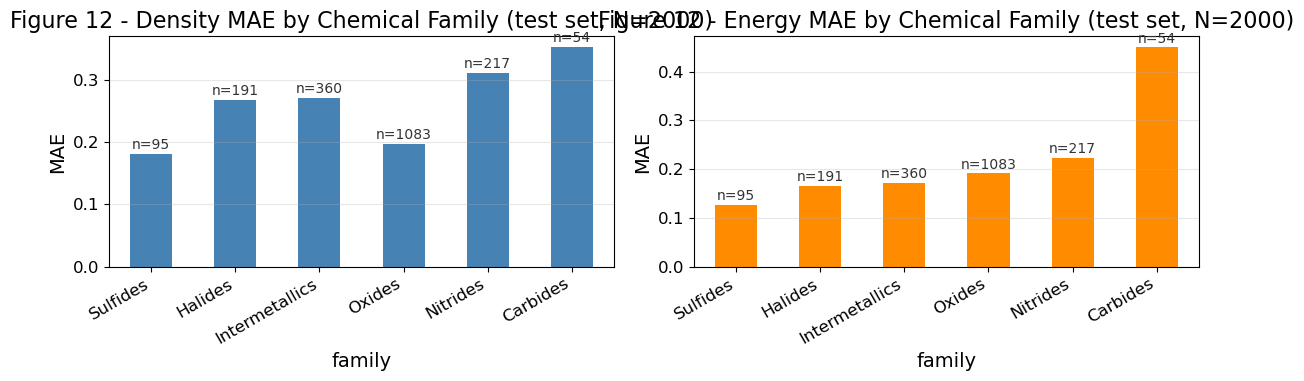

In [22]:
test_formulas = data["formula"].iloc[X_test.index].values
families      = [classify_family(f) for f in test_formulas]

df_fam = pd.DataFrame({
    "family":      families,
    "err_density": np.abs(yd_test.values - yd_xgb_pred),
    "err_energy":  np.abs(ye_test.values - ye_xgb_pred),
})
summary_fam = (
    df_fam.groupby("family")
    .agg(Count=("err_density","count"),
         MAE_Density=("err_density","mean"),
         MAE_Energy=("err_energy","mean"))
    .round(4)
    .sort_values("MAE_Energy")
)
print(f"Family-wise error breakdown (TEST SET ONLY, N={len(test_formulas)} - "
      f"NOT the full dataset; see Section 3 for the full-dataset family breakdown, N={len(data)}):")
print(summary_fam)
print()
print("Notes:")
print("  Carbides   - highest MAE but smallest n; error partly reflects small-sample noise.")
print("  Sulfides   - lowest MAE; bonding features well-represented in Magpie statistics.")
print("  Oxides     - dominate dataset and show mid-range MAE, anchoring overall metrics.")

# ── Figure 12 ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title, color in [
    (axes[0], "MAE_Density", "Density MAE by Chemical Family", "steelblue"),
    (axes[1], "MAE_Energy",  "Energy MAE by Chemical Family",  "darkorange"),
]:
    summary_fam[col].plot.bar(ax=ax, color=color)
    for i, (idx, row) in enumerate(summary_fam.iterrows()):
        ax.text(i, row[col] + 0.003, f"n={int(row.Count)}",
                ha="center", va="bottom", fontsize=10, color="#333333")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.grid(alpha=0.3, axis="y"); ax.set_ylabel("MAE")
    ax.set_title(f"Figure 12 - {title} (test set, N={len(test_formulas)})")
plt.tight_layout()
savefig("fig10_family_error_analysis.png")
plt.show()


## 16 - Novel Candidate Verification (Materials Project API)

Top candidates from virtual screening and inverse design are queried against the
Materials Project database. Candidates **absent** from the MP database are flagged
as **novel** — the primary deliverable of this pipeline.

> **Prerequisite:** Set `MP_API_KEY` as an environment variable before running.
> `export MP_API_KEY="your_api_key_here"`


In [20]:
if not MP_API_KEY:
    print("MP_API_KEY not set. Skipping verification.")
    print("Set the environment variable and re-run this cell.")
else:
    from mp_api.client import MPRester

    # Collect all formulas to verify
    screening_formulas = list(top10["formula"])
    inverse_formulas   = [cand_formulas_list[i] for i in top_inv_idx]
    all_to_verify      = list(dict.fromkeys(screening_formulas + inverse_formulas))

    print(f"Verifying {len(all_to_verify)} candidates against the Materials Project...\n")
    print(f"{'Formula':<16} {'Status':<40} {'Details'}")
    print("-" * 80)

    novel_candidates = []
    known_candidates = []

    with MPRester(MP_API_KEY) as mpr:
        for formula in all_to_verify:
            try:
                results = mpr.materials.summary.search(formula=formula)
            except Exception as e:
                print(f"{formula:<16} ERROR: {e}")
                continue

            if not results:
                novel_candidates.append(formula)
                print(f"{formula:<16} NOT in Materials Project - novel candidate")
            else:
                known_candidates.append(formula)
                for r in results:
                    print(f"{formula:<16} KNOWN  mp-id={r.material_id}"
                          f"  Ef={r.formation_energy_per_atom:.4f} eV/atom"
                          f"  E_hull={r.energy_above_hull:.4f}")

    print(f"\n{'=' * 60}")
    print(f"  Total verified    : {len(all_to_verify)}")
    print(f"  Novel candidates  : {len(novel_candidates)}")
    print(f"  Known compounds   : {len(known_candidates)}")
    print(f"\nNovel candidates (not in Materials Project):")
    for f in novel_candidates:
        if f in cand_formulas_list:
            i = cand_formulas_list.index(f)
            print(f"  {f:<16}  rho={cand_d_mean[i]:.3f}+/-{cp_q_d:.3f} g/cm3  "
                  f"Ef={cand_e_mean[i]:.3f}+/-{cp_q_e:.3f} eV/atom")


Verifying 18 candidates against the Materials Project...

Formula          Status                                   Details
--------------------------------------------------------------------------------


Retrieving SummaryDoc documents:   0%|          | 0/322 [00:00<?, ?it/s]

O2Si1            KNOWN  mp-id=mp-2374583  Ef=-3.1132 eV/atom  E_hull=0.1596
O2Si1            KNOWN  mp-id=mp-972808  Ef=-3.2509 eV/atom  E_hull=0.0163
O2Si1            KNOWN  mp-id=mp-985590  Ef=-3.2631 eV/atom  E_hull=0.0097
O2Si1            KNOWN  mp-id=mp-985570  Ef=-3.2644 eV/atom  E_hull=0.0085
O2Si1            KNOWN  mp-id=mp-1021503  Ef=-2.8757 eV/atom  E_hull=0.3971
O2Si1            KNOWN  mp-id=mp-1071820  Ef=-2.8304 eV/atom  E_hull=0.4425
O2Si1            KNOWN  mp-id=mp-1179447  Ef=-3.2495 eV/atom  E_hull=0.0234
O2Si1            KNOWN  mp-id=mp-1179454  Ef=-3.2540 eV/atom  E_hull=0.0188
O2Si1            KNOWN  mp-id=mp-1179508  Ef=-2.9368 eV/atom  E_hull=0.3360
O2Si1            KNOWN  mp-id=mp-1179488  Ef=-2.1724 eV/atom  E_hull=1.1004
O2Si1            KNOWN  mp-id=mp-1179529  Ef=-3.1001 eV/atom  E_hull=0.1727
O2Si1            KNOWN  mp-id=mp-1188220  Ef=-3.2563 eV/atom  E_hull=0.0165
O2Si1            KNOWN  mp-id=mp-1195265  Ef=-3.2552 eV/atom  E_hull=0.0177
O2Si1          

Retrieving SummaryDoc documents:   0%|          | 0/8 [00:00<?, ?it/s]

OCa1             KNOWN  mp-id=mp-1064492  Ef=-3.0961 eV/atom  E_hull=0.2099
OCa1             KNOWN  mp-id=mp-1079707  Ef=-3.0962 eV/atom  E_hull=0.2098
OCa1             KNOWN  mp-id=mp-1181903  Ef=-0.5779 eV/atom  E_hull=2.7281
OCa1             KNOWN  mp-id=mp-1244902  Ef=-2.9949 eV/atom  E_hull=0.3111
OCa1             KNOWN  mp-id=mp-1245200  Ef=-2.9645 eV/atom  E_hull=0.3415
OCa1             KNOWN  mp-id=mp-1245305  Ef=-3.0106 eV/atom  E_hull=0.2954
OCa1             KNOWN  mp-id=mp-2605  Ef=-3.3060 eV/atom  E_hull=0.0000
OCa1             KNOWN  mp-id=mp-545512  Ef=-3.2017 eV/atom  E_hull=0.1043


Retrieving SummaryDoc documents:   0%|          | 0/9 [00:00<?, ?it/s]

... (13 outputs left out)

Retrieving SummaryDoc documents:   0%|          | 0/5 [00:00<?, ?it/s]

Cl3Cr1           KNOWN  mp-id=mp-1192095  Ef=-1.2917 eV/atom  E_hull=0.3025
Cl3Cr1           KNOWN  mp-id=mp-1193047  Ef=-1.2715 eV/atom  E_hull=0.3227
Cl3Cr1           KNOWN  mp-id=mp-27630  Ef=-1.5936 eV/atom  E_hull=0.0005
Cl3Cr1           KNOWN  mp-id=mp-567504  Ef=-1.5942 eV/atom  E_hull=0.0000
Cl3Cr1           KNOWN  mp-id=mp-569890  Ef=-1.5874 eV/atom  E_hull=0.0068
Fe1F1Te1         NOT in Materials Project - novel candidate


Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Ce2Se3           KNOWN  mp-id=mp-32578  Ef=-2.1007 eV/atom  E_hull=0.0000

  Total verified    : 18
  Novel candidates  : 7
  Known compounds   : 11

Novel candidates (not in Materials Project):
  P1F1O2            rho=2.269+/-0.590 g/cm3  Ef=-2.016+/-0.472 eV/atom
  C1O2S1            rho=1.981+/-0.590 g/cm3  Ef=-1.308+/-0.472 eV/atom
  F2S1Si1           rho=2.467+/-0.590 g/cm3  Ef=-3.488+/-0.472 eV/atom
  O1S1Mg2           rho=2.429+/-0.590 g/cm3  Ef=-1.986+/-0.472 eV/atom
  Ca1S2Be1          rho=2.555+/-0.590 g/cm3  Ef=-1.623+/-0.472 eV/atom
  N1Cl1Mg1          rho=2.381+/-0.590 g/cm3  Ef=-1.711+/-0.472 eV/atom
  Fe1F1Te1          rho=2.259+/-0.590 g/cm3  Ef=-1.680+/-0.472 eV/atom


---

## Conclusion

This notebook presented a reliability-aware ML pipeline for predicting density and
formation energy of lightweight solid materials. Key contributions:

1. **LOCO evaluation** reveals that random-split R2 systematically overstates out-of-distribution generalisation.
2. **Conformal prediction** provides distribution-free 90% prediction intervals with guaranteed empirical coverage.
3. **Applicability Domain** quantifies when predictions should not be trusted; outside-AD errors are significantly higher.
4. **Virtual Screening + Inverse Design** identifies novel lightweight solid candidates not present in the Materials Project, verified via the MP API.

### Limitations & Future Work

- Composition-only Magpie features cannot distinguish crystal polymorphs; a structure-aware featuriser (MEGNet, CGCNN) would improve density R2.
- The charge-balance filter assumes common oxidation states; less-common valences may produce false positives/negatives.
- Experimental synthesis and characterisation of proposed novel candidates is required to validate predictions.

### References

- Jha, D. et al. "ElemNet." *Scientific Reports* 8, 2018.
- Goodall, R.E.A. & Lee, A.A. "Predicting materials properties without crystal structure." *Nature Communications* 11, 2020.
- Angelopoulos, A.N. & Bates, S. "A Gentle Introduction to Conformal Prediction." *arXiv*:2107.07511, 2022.
- Ong, S.P. et al. "Python Materials Genomics (pymatgen)." *Computational Materials Science* 68, 2013.
- Ward, L. et al. "Matminer." *Computational Materials Science* 152, 2018.
